In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import cv2

from collections import Counter
from sklearn.metrics import classification_report
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from tensorflow.keras.datasets import cifar10

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Convert labels into 1D arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("Dataset Loaded Successfully!")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 598s 4us/step
Dataset Loaded Successfully!
Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [3]:
print("========== DATASET INFORMATION ==========")

print("Total Images:", len(X_train) + len(X_test))
print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("Image Height:", X_train.shape[1])
print("Image Width:", X_train.shape[2])
print("Number of Channels:", X_train.shape[3])

print("Number of Classes:", len(class_names))

print("\nClass Names:")
for i, name in enumerate(class_names):
    print(i, ":", name)

========== DATASET INFORMATION ==========
Total Images: 60000
Training Images: 50000
Testing Images: 10000
Image Height: 32
Image Width: 32
Number of Channels: 3
Number of Classes: 10

Class Names:
0 : Airplane
1 : Automobile
2 : Bird
3 : Cat
4 : Deer
5 : Dog
6 : Frog
7 : Horse
8 : Ship
9 : Truck


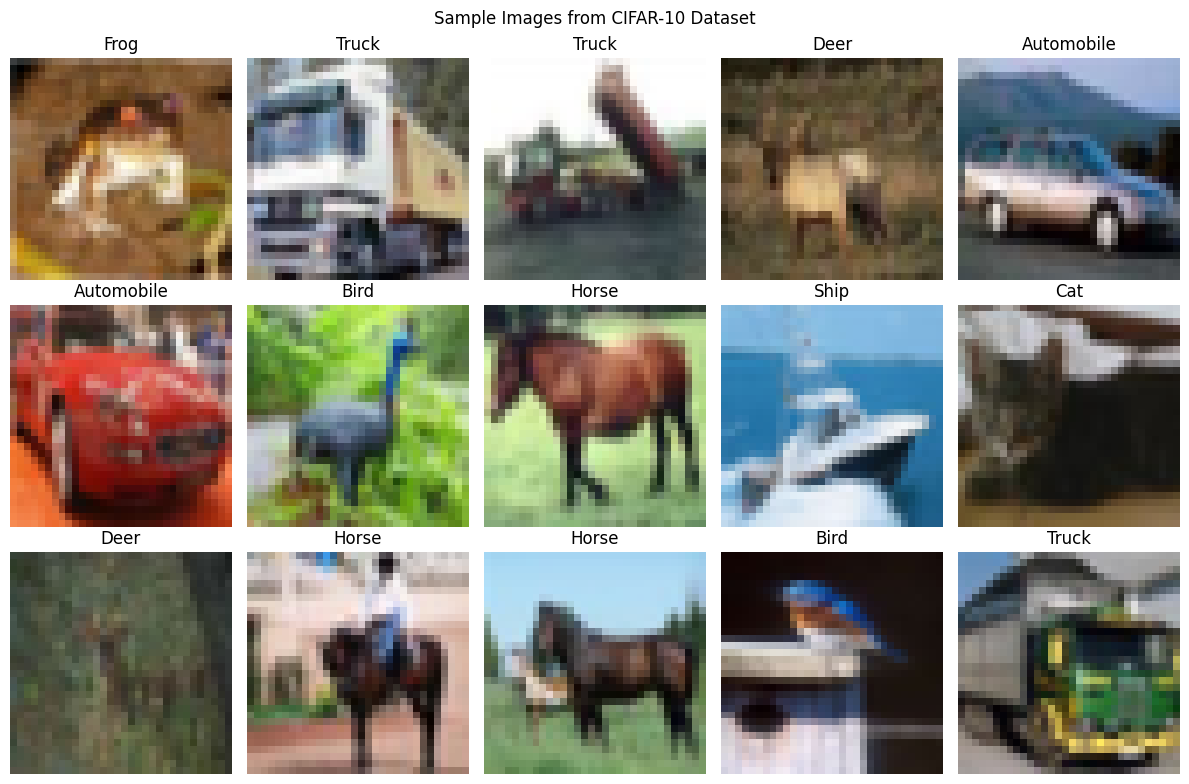

In [4]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle("Sample Images from CIFAR-10 Dataset")
plt.tight_layout()
plt.show()

        Class  Image Count
0    Airplane         5000
1  Automobile         5000
2        Bird         5000
3         Cat         5000
4        Deer         5000
5         Dog         5000
6        Frog         5000
7       Horse         5000
8        Ship         5000
9       Truck         5000


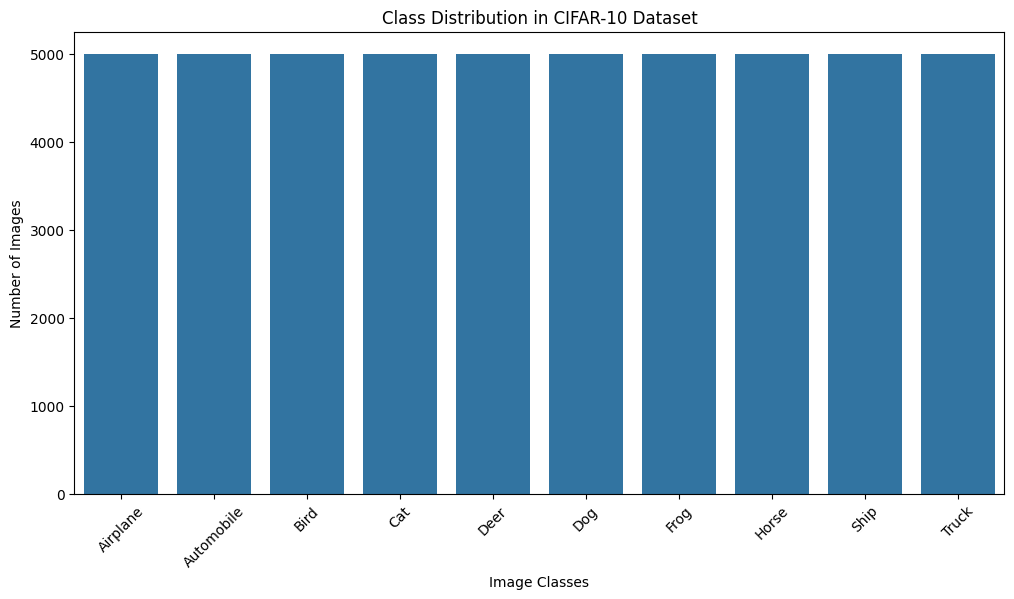

In [5]:
class_counts = Counter(y_train)

distribution = pd.DataFrame({
    'Class': class_names,
    'Image Count': [
        class_counts[i] for i in range(10)
    ]
})

print(distribution)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=distribution,
    x='Class',
    y='Image Count'
)

plt.title("Class Distribution in CIFAR-10 Dataset")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [6]:
quality_data = []

for i in range(len(X_train)):
    image = X_train[i]

    # Calculate brightness
    brightness = np.mean(image)

    # Calculate image dimensions
    height, width, channels = image.shape

    # Calculate blur using Laplacian variance
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    quality_data.append({
        'Image_ID': i,
        'Brightness': brightness,
        'Height': height,
        'Width': width,
        'Blur_Score': blur_score
    })

quality_df = pd.DataFrame(quality_data)

print(quality_df.head())

print("\nAverage Brightness:",
      quality_df['Brightness'].mean())

print("Average Blur Score:",
      quality_df['Blur_Score'].mean())

print("Image Dimensions:",
      quality_df[['Height', 'Width']].drop_duplicates())

   Image_ID  Brightness  Height  Width   Blur_Score
0         0  103.447266      32     32  2437.326858
1         1  130.347331      32     32  5685.193702
2         2  133.740560      32     32  1785.769958
3         3   80.224284      32     32  1391.596068
4         4  103.474935      32     32  2881.055465

Average Brightness: 120.7075651236979
Average Blur Score: 2416.2460627178766
Image Dimensions:    Height  Width
0      32     32


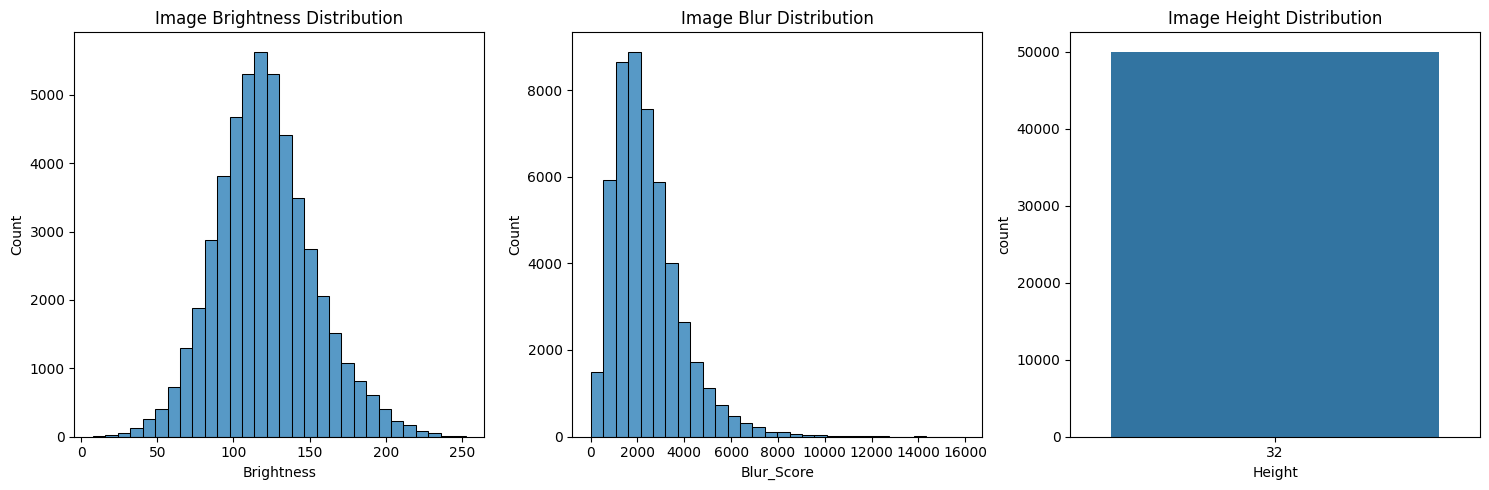

In [7]:
plt.figure(figsize=(15, 5))

# Brightness distribution
plt.subplot(1, 3, 1)
sns.histplot(quality_df['Brightness'], bins=30)
plt.title("Image Brightness Distribution")

# Blur distribution
plt.subplot(1, 3, 2)
sns.histplot(quality_df['Blur_Score'], bins=30)
plt.title("Image Blur Distribution")

# Image dimensions
plt.subplot(1, 3, 3)
sns.countplot(
    x=quality_df['Height'].astype(str)
)
plt.title("Image Height Distribution")

plt.tight_layout()
plt.show()

In [8]:
from collections import defaultdict

image_hashes = defaultdict(list)

for i, image in enumerate(X_train):
    image_hash = hash(image.tobytes())
    image_hashes[image_hash].append(i)

duplicates = {
    key: indices
    for key, indices in image_hashes.items()
    if len(indices) > 1
}

print("Number of Duplicate Groups:", len(duplicates))

duplicate_count = sum(
    len(indices) - 1
    for indices in duplicates.values()
)

print("Total Extra Duplicate Images:", duplicate_count)

if duplicate_count == 0:
    print("No exact duplicate images found.")

Number of Duplicate Groups: 0
Total Extra Duplicate Images: 0
No exact duplicate images found.


In [9]:
print("========== ANNOTATION VALIDATION ==========")

# Check missing labels
missing_labels = np.isnan(y_train).sum()

# Check invalid labels
invalid_labels = np.sum(
    (y_train < 0) | (y_train >= len(class_names))
)

# Check label count
label_count = len(y_train)

# Check image-label matching
image_label_match = len(X_train) == len(y_train)

print("Missing Labels:", missing_labels)
print("Invalid Labels:", invalid_labels)
print("Total Labels:", label_count)

print("Image and Label Count Match:",
      image_label_match)

if missing_labels == 0 and invalid_labels == 0:
    print("\nAnnotation Validation: PASSED")
else:
    print("\nAnnotation Validation: FAILED")

========== ANNOTATION VALIDATION ==========
Missing Labels: 0
Invalid Labels: 0
Total Labels: 50000
Image and Label Count Match: True

Annotation Validation: PASSED


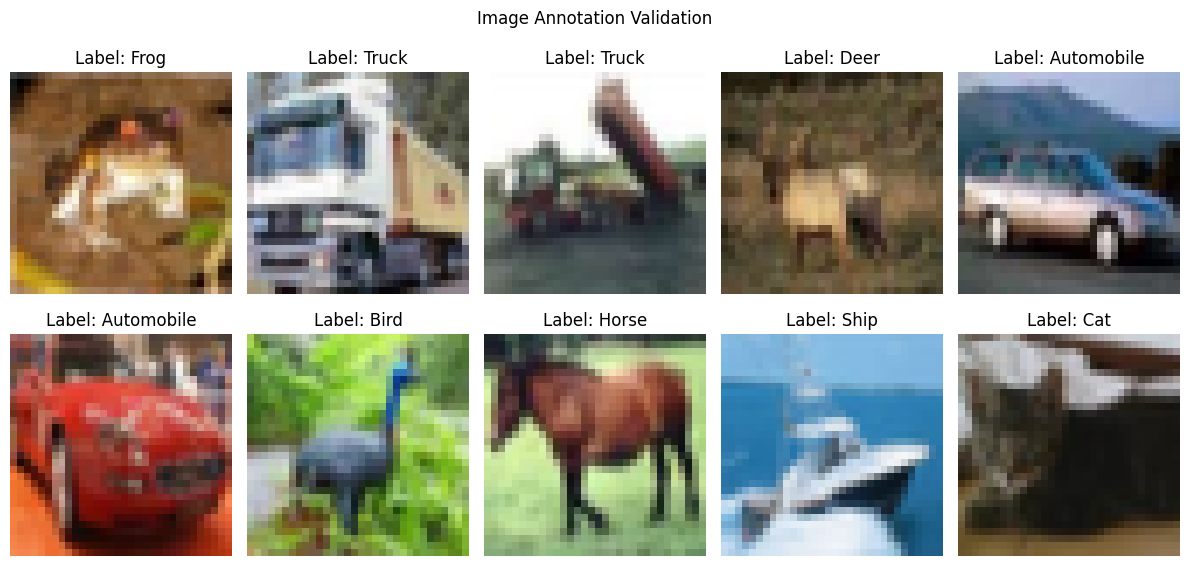

In [10]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_train[i]
    label = y_train[i]

    plt.imshow(image)
    plt.title("Label: " + class_names[label])
    plt.axis('off')

plt.suptitle("Image Annotation Validation")
plt.tight_layout()
plt.show()

In [11]:
print("======================================")
print("       DATASET AUDIT REPORT")
print("======================================")

print("\n1. DATASET INFORMATION")
print("Total Images:", len(X_train) + len(X_test))
print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("\n2. CLASS DISTRIBUTION")
print(distribution)

print("\n3. IMAGE QUALITY")
print("Average Brightness:",
      round(quality_df['Brightness'].mean(), 2))

print("Average Blur Score:",
      round(quality_df['Blur_Score'].mean(), 2))

print("\n4. DUPLICATE DETECTION")
print("Duplicate Groups:", len(duplicates))
print("Extra Duplicate Images:", duplicate_count)

print("\n5. ANNOTATION VALIDATION")
print("Missing Labels:", missing_labels)
print("Invalid Labels:", invalid_labels)
print("Image-Label Match:", image_label_match)

print("\n======================================")
print("       DATASET AUDIT COMPLETED")
print("======================================")

       DATASET AUDIT REPORT

1. DATASET INFORMATION
Total Images: 60000
Training Images: 50000
Testing Images: 10000

2. CLASS DISTRIBUTION
        Class  Image Count
0    Airplane         5000
1  Automobile         5000
2        Bird         5000
3         Cat         5000
4        Deer         5000
5         Dog         5000
6        Frog         5000
7       Horse         5000
8        Ship         5000
9       Truck         5000

3. IMAGE QUALITY
Average Brightness: 120.71
Average Blur Score: 2416.25

4. DUPLICATE DETECTION
Duplicate Groups: 0
Extra Duplicate Images: 0

5. ANNOTATION VALIDATION
Missing Labels: 0
Invalid Labels: 0
Image-Label Match: True

       DATASET AUDIT COMPLETED


In [12]:
quality_df.to_csv(
    "image_quality_report.csv",
    index=False
)

distribution.to_csv(
    "class_distribution_report.csv",
    index=False
)

print("Audit reports saved successfully!")

print("1. image_quality_report.csv")
print("2. class_distribution_report.csv")

Audit reports saved successfully!
1. image_quality_report.csv
2. class_distribution_report.csv
